# 06 · Interacciones de FE en el conjunto JAE

**Objetivo:** medir si las cuatro variables que solo tenía el conjunto FE
(`features.features`) mejoran el conjunto JAE, y si con ellas se supera a la
entrega B del notebook 05.

| Variable | Qué es |
| --- | --- |
| `age_x_util` | Edad × utilización (recortada a 2) |
| `late_x_util` | Total de atrasos × utilización |
| `non_re_lines` | Líneas abiertas − créditos hipotecarios |
| `max_late` | Máximo de los tres atrasos |

Se calculan en `engineering_jae.add_fixed_features()` sobre los datos limpios
del módulo (atrasos con códigos 96/98 en 0 y recortados a 6) y entran al
modelo con `FeatureConfig(interactions=True)`. Según la comparación de
`docs/aprendizajes_iteracion_05.md` (sección 4), son la explicación más
probable de que el conjunto FE rindiera +0.00025 más que el JAE.

**Trazabilidad.** Igual que en el notebook 05: cada iteración cambia una sola
cosa, lleva antes un bloque de comentarios con la iteración previa
(dataset, hiperparámetros y AUC) y `verificar_previa()` comprueba que el AUC
del comentario coincide con el calculado. La traza se guarda en
`data/processed/jae/traza_06.json`.

**Punto de partida sin reentrenar.** Las entregas A y B y el modelo FE del
notebook 05 se leen de sus predicciones OOF (`oof_mejora_05.parquet`). Como
son predicciones fuera de fold con la misma partición, el AUC por fold se
recalcula exactamente y la comparación pareada sigue siendo válida.

## 0. Preparación

In [1]:
import json
import logging
import sys
from collections.abc import Callable
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

# El notebook vive en notebooks/: se agrega src/ al path para importar los módulos
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from evaluation import RANDOM_STATE, get_cv, read_log  # noqa: E402
from evaluation.oof_jae import (  # noqa: E402
    ResultadoCV,
    combinar_resultados,
    evaluar_modelo,
    graficar_roc_oof,
    registrar_en_bitacora,
)
from features.engineering_jae import (  # noqa: E402
    ID,
    INTERACTION_FEATURES,
    TARGET,
    FeatureConfig,
    build_preprocessor,
    prepare_fixed,
)
from features.features import prepare  # noqa: E402

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

SEMILLA = RANDOM_STATE  # semilla compartida del equipo (985)
SEMILLAS = [985, 1, 2, 3, 4]  # mismas semillas que el notebook 05
SALIDA = ROOT / "data" / "processed" / "jae"

## 1. Datos y conjuntos de variables

| Conjunto | Origen | Contenido |
| --- | --- | --- |
| **JAE** | `FeatureConfig(for_trees=True, impute_for_trees=False)` | 23 variables (entrega A del notebook 05) |
| **JAE + interacciones** | La misma configuración con `interactions=True` | 27 variables: las 23 de JAE + las 4 interacciones |
| **FE** | `features.features.prepare()` | 28 variables (segundo miembro de la entrega B) |

In [2]:
train_raw = pd.read_csv(ROOT / "data/raw/train.csv")
test_raw = pd.read_csv(ROOT / "data/raw/test.csv")
muestra = pd.read_csv(ROOT / "data/raw/sample_submission.csv")
y = train_raw[TARGET]

# Transformaciones fijas; las interacciones ya vienen en prepare_fixed()
X_jae = prepare_fixed(train_raw.drop(columns=[TARGET, ID]))
X_jae_test = prepare_fixed(test_raw.drop(columns=[ID]))
CONFIG_JAE = FeatureConfig(for_trees=True, impute_for_trees=False)
CONFIG_JAE_INT = FeatureConfig(
    for_trees=True, impute_for_trees=False, interactions=True
)

X_fe = prepare(train_raw)
X_fe_test = prepare(test_raw)

columnas_int = build_preprocessor(CONFIG_JAE_INT).fit(X_jae, y).transform(X_jae).columns
assert set(INTERACTION_FEATURES) <= set(columnas_int), "Faltan las interacciones"
DATASET_JAE = "JAE: engineering_jae árboles (23 variables, NaN nativo)"
DATASET_JAE_INT = (
    f"JAE + interacciones: engineering_jae árboles ({len(columnas_int)} variables, "
    "NaN nativo)"
)
DATASET_FE = f"FE: features.prepare() ({X_fe.shape[1]} variables, NaN nativo)"
print(f"train: {len(train_raw):,} filas · test: {len(test_raw):,} filas")
print(DATASET_JAE_INT)
print("Variables nuevas:", INTERACTION_FEATURES)

train: 105,000 filas · test: 45,000 filas
JAE + interacciones: engineering_jae árboles (27 variables, NaN nativo)
Variables nuevas: ['age_x_util', 'late_x_util', 'non_re_lines', 'max_late']


**Control de calidad de las interacciones:** se comparan contra las mismas
variables de `features.prepare()`. Solo deben diferir en las filas donde JAE
limpia los atrasos (códigos 96/98 → 0 y recorte a 6), y el orden debe ser
el mismo, que es lo único que le importa a un árbol.

In [3]:
control = pd.DataFrame(
    {
        variable: {
            "filas distintas a FE (%)": 100
            * float((X_jae[variable].fillna(-1) != X_fe[variable].fillna(-1)).mean()),
            "Spearman con FE": X_jae[variable].corr(X_fe[variable], method="spearman"),
            "faltantes": int(X_jae[variable].isna().sum()),
            "mínimo": X_jae[variable].min(),
            "máximo": X_jae[variable].max(),
        }
        for variable in INTERACTION_FEATURES
    }
).T
assert (
    control["Spearman con FE"] > 0.999
).all(), "Las interacciones no coinciden con FE"
display(control.round(4))

,filas distintas a FE (%),Spearman con FE,faltantes,mínimo,máximo
age_x_util,0.0000,1.0,1.0,0.0,172.0
late_x_util,0.1476,1.0,0.0,0.0,22.0
non_re_lines,0.0000,1.0,0.0,0.0,57.0
max_late,0.3371,1.0,0.0,0.0,6.0


## 2. Herramientas de trazabilidad
Las mismas del notebook 05 (`clasificador`, `verificar_previa`,
`registrar_iteracion`, evaluación y predicción por semilla), más
`resultado_desde_oof()` para partir de las predicciones guardadas.

In [4]:
# Hiperparámetros del experimento 2b (notebook 04); base de los notebooks 05 y 06
PARAMETROS_2B = {
    "max_depth": 6,
    "min_child_weight": 10,
    "subsample": 0.6,
    "colsample_bytree": 0.7,
    "reg_lambda": 10.0,
    "gamma": 0.5,
}
LEARNING_RATE = 0.01
ARBOLES_JAE = 764  # elegidos por early stopping en la iteración 1 del notebook 05
ARBOLES_FE = 777  # elegidos por early stopping en la iteración 3 del notebook 05
TOLERANCIA_AUC = 5e-5

traza: list[dict] = []
resultados: dict[str, ResultadoCV] = {}
folds = list(get_cv().split(X_jae, y))


def clasificador(**parametros: object) -> XGBClassifier:
    """Crea un XGBoost con los hiperparámetros de 2b y los cambios indicados.

    Args:
        **parametros: Parámetros que reemplazan o complementan a los de 2b.

    Returns:
        Clasificador sin ajustar.
    """
    base = {
        "eval_metric": "auc",
        "tree_method": "hist",
        "random_state": SEMILLA,
        "n_jobs": -1,
        "learning_rate": LEARNING_RATE,
        **PARAMETROS_2B,
    }
    base.update(parametros)
    return XGBClassifier(**base)


def modelo_jae(config: FeatureConfig, **parametros: object) -> Pipeline:
    """Arma el pipeline JAE: preprocesamiento para árboles + XGBoost.

    Args:
        config: Configuración de variables (con o sin interacciones).
        **parametros: Parámetros de :func:`clasificador`.

    Returns:
        Pipeline sin ajustar.
    """
    return Pipeline(
        [("prep", build_preprocessor(config)), ("clf", clasificador(**parametros))]
    )


def resultado_desde_oof(nombre: str, oof: np.ndarray) -> ResultadoCV:
    """Reconstruye un resultado de validación cruzada a partir de predicciones OOF.

    Args:
        nombre: Nombre del experimento.
        oof: Predicciones fuera de fold, en el orden de ``train``.

    Returns:
        Resultado con el AUC por fold recalculado. El AUC de entrenamiento no se
        guardó, así que queda como ``NaN``.
    """
    curvas = [(y.iloc[va].to_numpy(), oof[va]) for _, va in folds]
    return ResultadoCV(
        nombre=nombre,
        auc_folds=np.array([roc_auc_score(y_va, p) for y_va, p in curvas]),
        auc_train_folds=np.full(len(folds), np.nan),
        oof=oof,
        auc_oof=float(roc_auc_score(y, oof)),
        tiempo_s=0.0,
        curvas=curvas,
    )


def verificar_previa(clave: str, auc_comentado: float) -> None:
    """Comprueba que el AUC anotado en el comentario coincide con el calculado.

    Args:
        clave: Clave de la iteración previa en ``resultados``.
        auc_comentado: AUC de validación escrito en el comentario.

    Raises:
        AssertionError: Si la diferencia supera ``TOLERANCIA_AUC``.
    """
    calculado = resultados[clave].auc_media
    assert abs(calculado - auc_comentado) <= TOLERANCIA_AUC, (
        f"El comentario dice {auc_comentado:.5f} y la iteración {clave} "
        f"dio {calculado:.5f}: actualizar el bloque de trazabilidad"
    )
    print(
        f"✅ Iteración previa {clave}: AUC {calculado:.5f} (coincide con el comentario)"
    )


def registrar_iteracion(
    clave: str,
    previa: str | None,
    cambio: str,
    dataset: str,
    hiperparametros: str,
) -> pd.DataFrame:
    """Agrega una iteración a la traza y la compara fold por fold con la previa.

    Args:
        clave: Clave de la iteración en ``resultados``.
        previa: Clave de la iteración de la que parte; ``None`` para la base.
        cambio: Único cambio introducido respecto a la previa.
        dataset: Conjunto de variables usado.
        hiperparametros: Hiperparámetros que la distinguen.

    Returns:
        Tabla con la iteración y su comparación pareada contra la previa.
    """
    resultado = resultados[clave]
    fila = {
        "iteración": clave,
        "experimento": resultado.nombre,
        "parte de": previa or "—",
        "cambio": cambio,
        "dataset": dataset,
        "hiperparámetros": hiperparametros,
        "AUC": round(resultado.auc_media, 5),
        "desv": round(resultado.auc_std, 5),
        "AUC OOF": round(resultado.auc_oof, 5),
    }
    if previa is not None:
        fila.update(comparar(clave, previa, prefijo="previa"))
    traza.append(fila)
    return pd.DataFrame([fila]).set_index("iteración").T


def comparar(clave: str, referencia: str, prefijo: str) -> dict[str, object]:
    """Compara dos iteraciones fold por fold (comparación pareada).

    Args:
        clave: Iteración a evaluar.
        referencia: Iteración contra la que se compara.
        prefijo: Texto para nombrar las columnas (por ejemplo, ``previa``).

    Returns:
        AUC de la referencia, diferencia media, error estándar y folds ganados.
    """
    diferencia = resultados[clave].auc_folds - resultados[referencia].auc_folds
    return {
        f"AUC {prefijo}": round(resultados[referencia].auc_media, 5),
        f"Δ vs {prefijo}": round(float(diferencia.mean()), 5),
        "error estándar": round(float(diferencia.std(ddof=1) / np.sqrt(len(folds))), 5),
        "folds en que gana": f"{int((diferencia > 0).sum())}/{len(folds)}",
    }


def evaluar_semillas(
    crear_modelo: Callable[[int], object], X: pd.DataFrame, prefijo: str
) -> list[ResultadoCV]:
    """Evalúa el mismo modelo con cada semilla de ``SEMILLAS``.

    Args:
        crear_modelo: Función que recibe una semilla y devuelve el modelo sin
            ajustar.
        X: Variables de entrada.
        prefijo: Prefijo del nombre de cada experimento.

    Returns:
        Un resultado de validación cruzada por semilla.
    """
    return [
        evaluar_modelo(crear_modelo(semilla), X, y, f"{prefijo} · semilla {semilla}")
        for semilla in SEMILLAS
    ]


def tabla_semillas(miembros: list[ResultadoCV], promedio: ResultadoCV) -> pd.DataFrame:
    """Compara el AUC de cada semilla con el del promedio.

    Args:
        miembros: Resultados individuales por semilla.
        promedio: Resultado de promediar sus predicciones.

    Returns:
        Tabla con AUC de validación, desviación y AUC OOF.
    """
    todos = [*miembros, promedio]
    return pd.DataFrame(
        {
            "AUC validación": [r.auc_media for r in todos],
            "desv": [r.auc_std for r in todos],
            "AUC OOF": [r.auc_oof for r in todos],
        },
        index=[*[f"semilla {s}" for s in SEMILLAS], "promedio de 5 semillas"],
    )

## 3. Iteración 0: punto de partida (notebook 05)
Se leen las predicciones OOF de la entrega A, del modelo FE y de la entrega
B, y se verifica que reproducen los AUC registrados en la bitácora.

In [5]:
# ─── TRAZABILIDAD · PUNTO DE PARTIDA (notebook 05) ──────────────────────────
# Entrega A:        jae_3b_entrega_a_semillas
#   Dataset:        JAE: engineering_jae árboles (23 variables, NaN nativo)
#   Hiperparámetros: learning_rate=0.01 + parámetros 2b; 764 árboles;
#                   promedio de 5 semillas (985, 1, 2, 3, 4)
#   AUC (CV):       0.86638 ± 0.00289
# Modelo FE:        jae_4_xgboost_fe_semillas
#   Dataset:        FE: features.prepare() (28 variables, NaN nativo)
#   Hiperparámetros: learning_rate=0.01 + parámetros 2b; 777 árboles; 5 semillas
#   AUC (CV):       0.86663 ± 0.00280
# Entrega B:        jae_5_entrega_b_mezcla (mezcla 50/50 de A y FE)
#   AUC (CV):       0.86663 (mejor puntaje público del equipo: 0.88012)
# ────────────────────────────────────────────────────────────────────────────
oof_05 = pd.read_parquet(SALIDA / "oof_mejora_05.parquet")
assert (oof_05[ID].to_numpy() == train_raw[ID].to_numpy()).all(), "Orden distinto"
assert (oof_05[TARGET].to_numpy() == y.to_numpy()).all(), "Objetivo distinto"

resultados["A"] = resultado_desde_oof(
    "jae_3b_entrega_a_semillas", oof_05["oof_entrega_a"].to_numpy()
)
resultados["FE"] = resultado_desde_oof(
    "jae_4_xgboost_fe_semillas", oof_05["oof_fe"].to_numpy()
)
resultados["B"] = resultado_desde_oof(
    "jae_5_entrega_b_mezcla", oof_05["oof_entrega_b"].to_numpy()
)

bitacora = read_log().set_index("nombre")["cv_auc_mean"]
for clave in ("A", "FE", "B"):
    nombre = resultados[clave].nombre
    assert abs(bitacora[nombre] - resultados[clave].auc_media) <= TOLERANCIA_AUC, nombre
verificar_previa("A", 0.86638)
verificar_previa("FE", 0.86663)
verificar_previa("B", 0.86663)
registrar_iteracion(
    "A",
    None,
    "entrega A del notebook 05",
    DATASET_JAE,
    f"lr=0.01, 2b, {ARBOLES_JAE} árboles, 5 semillas",
)

✅ Iteración previa A: AUC 0.86638 (coincide con el comentario)
✅ Iteración previa FE: AUC 0.86663 (coincide con el comentario)
✅ Iteración previa B: AUC 0.86663 (coincide con el comentario)


iteración,A
experimento,jae_3b_entrega_a_semillas
parte de,—
cambio,entrega A del notebook 05
dataset,"JAE: engineering_jae árboles (23 variables, NaN nativo)"
hiperparámetros,"lr=0.01, 2b, 764 árboles, 5 semillas"
AUC,0.86638
desv,0.00289
AUC OOF,0.86627


## 4. Iteración 1: JAE + interacciones
Se repite exactamente la entrega A cambiando solo el conjunto de variables:
las 23 de JAE más las 4 interacciones. Se conservan los 764 árboles fijos
para que el único cambio sea el de las variables.

In [6]:
# ─── TRAZABILIDAD · ITERACIÓN PREVIA (A) · ENTREGA A ────────────────────────
# Experimento:      jae_3b_entrega_a_semillas
# Dataset:          JAE: engineering_jae árboles (23 variables, NaN nativo)
# Hiperparámetros:  learning_rate=0.01 + parámetros 2b; 764 árboles;
#                   promedio de 5 semillas (985, 1, 2, 3, 4)
# AUC previo (CV):  0.86638 ± 0.00289
# ─── ESTA ITERACIÓN (1) ─────────────────────────────────────────────────────
# Cambio:           dataset JAE → JAE + interacciones (age_x_util,
#                   late_x_util, non_re_lines, max_late)
# Se mantiene:      learning_rate=0.01, parámetros 2b, 764 árboles, 5 semillas
#                   y partición
# ────────────────────────────────────────────────────────────────────────────
verificar_previa("A", 0.86638)

semillas_int = evaluar_semillas(
    lambda semilla: modelo_jae(
        CONFIG_JAE_INT, n_estimators=ARBOLES_JAE, random_state=semilla
    ),
    X_jae,
    "jae + interacciones xgboost lr=0.01",
)
resultados["1"] = combinar_resultados(semillas_int, y, "jae_6_interacciones_semillas")
display(tabla_semillas(semillas_int, resultados["1"]).round(5))
registrar_iteracion(
    "1",
    "A",
    "dataset JAE → JAE + 4 interacciones de FE",
    DATASET_JAE_INT,
    f"lr=0.01, 2b, {ARBOLES_JAE} árboles, semillas {SEMILLAS}",
)

✅ Iteración previa A: AUC 0.86638 (coincide con el comentario)


,AUC validación,desv,AUC OOF
semilla 985,0.86645,0.00295,0.86632
semilla 1,0.86643,0.00282,0.86631
semilla 2,0.86656,0.00275,0.86645
semilla 3,0.86640,0.00297,0.86629
semilla 4,0.86643,0.00289,0.86632
promedio de 5 semillas,0.86653,0.00287,0.86642


iteración,1
experimento,jae_6_interacciones_semillas
parte de,A
cambio,dataset JAE → JAE + 4 interacciones de FE
dataset,"JAE + interacciones: engineering_jae árboles (27 variables, NaN nativo)"
hiperparámetros,"lr=0.01, 2b, 764 árboles, semillas [985, 1, 2, 3, 4]"
AUC,0.86653
desv,0.00287
AUC OOF,0.86642
AUC previa,0.86638
Δ vs previa,0.00015


**Comparación contra el modelo FE.** Si las interacciones explicaban la
ventaja de FE, el conjunto JAE + interacciones debería alcanzarlo.

In [7]:
pd.DataFrame(
    {
        "contra la entrega A": comparar("1", "A", "referencia"),
        "contra el modelo FE": comparar("1", "FE", "referencia"),
        "contra la entrega B": comparar("1", "B", "referencia"),
    }
)

,contra la entrega A,contra el modelo FE,contra la entrega B
AUC referencia,0.86638,0.86663,0.86663
Δ vs referencia,0.00015,-0.0001,-0.00009
error estándar,0.00019,0.00011,0.00014
folds en que gana,3/5,1/5,3/5


**Lectura:** las interacciones mejoran al conjunto JAE, pero
poco.
- **Contra la entrega A:** 0.86653 contra 0.86638, +0.00015 con error
  estándar de 0.00019; gana en 3 de 5 folds. Es una mejora dentro del ruido.
- **Contra el modelo FE:** −0.00010 (gana en 1 de 5). Las interacciones
  cierran cerca del 60 % de la distancia entre JAE y FE, pero no toda: el
  resto de la ventaja de FE no viene de estas cuatro variables (por ejemplo,
  de las variables crudas sin recortar que FE conserva).
- **Contra la entrega B:** −0.00009 (gana en 3 de 5). Un solo modelo JAE con
  interacciones queda prácticamente empatado con la mezcla.
- Las cinco semillas quedan entre 0.86640 y 0.86656: el modelo es estable.

## 5. Iteración 2: mezcla JAE + interacciones con FE (entrega C)
Misma receta que la entrega B, sustituyendo la entrega A por la iteración 1.

In [8]:
# ─── TRAZABILIDAD · ITERACIÓN PREVIA (B) · ENTREGA B ────────────────────────
# Experimento:      jae_5_entrega_b_mezcla
# Miembros:         entrega A (JAE, 0.86638) + modelo FE (0.86663), 50/50
# AUC previo (CV):  0.86663 (mejor puntaje público del equipo: 0.88012)
# ─── PRIMER MIEMBRO DE LA MEZCLA (1) ────────────────────────────────────────
# Experimento:      jae_6_interacciones_semillas
# Dataset:          JAE + interacciones (27 variables, NaN nativo)
# AUC (CV):         0.86653 ± 0.00287
# ─── ESTA ITERACIÓN (2) · ENTREGA C ─────────────────────────────────────────
# Cambio:           primer miembro de la mezcla: entrega A → iteración 1
# Se mantiene:      modelo FE como segundo miembro; pesos 0.5 y 0.5
# ────────────────────────────────────────────────────────────────────────────
verificar_previa("B", 0.86663)
verificar_previa("1", 0.86653)

resultados["2"] = combinar_resultados(
    [resultados["1"], resultados["FE"]], y, "jae_7_entrega_c_mezcla"
)
correlacion = pd.Series(resultados["1"].oof).corr(
    pd.Series(resultados["FE"].oof), method="spearman"
)
print(
    f"Spearman entre las predicciones OOF de JAE + interacciones y FE: {correlacion:.4f}"
)
registrar_iteracion(
    "2",
    "B",
    "mezcla 50/50: entrega A → JAE + interacciones",
    f"{DATASET_JAE_INT} + {DATASET_FE}",
    f"lr=0.01, 2b, {ARBOLES_JAE} y {ARBOLES_FE} árboles, 5 semillas c/u",
)

✅ Iteración previa B: AUC 0.86663 (coincide con el comentario)
✅ Iteración previa 1: AUC 0.86653 (coincide con el comentario)
Spearman entre las predicciones OOF de JAE + interacciones y FE: 0.9986


iteración,2
experimento,jae_7_entrega_c_mezcla
parte de,B
cambio,mezcla 50/50: entrega A → JAE + interacciones
dataset,"JAE + interacciones: engineering_jae árboles (27 variables, NaN nativo) + FE: features.prepare() (28 variables, NaN nativo)"
hiperparámetros,"lr=0.01, 2b, 764 y 777 árboles, 5 semillas c/u"
AUC,0.86666
desv,0.00284
AUC OOF,0.86655
AUC previa,0.86663
Δ vs previa,0.00003


**Lectura:** la entrega C empata con la entrega B.
- **0.86666 contra 0.86663:** +0.00003, con error estándar de 0.00009, y gana
  en 3 de 5 folds. La diferencia es mucho menor que el ruido.
- **Hay aún menos diversidad que en la entrega B:** al agregar las
  interacciones, el modelo JAE se parece más al FE (Spearman 0.9986 contra
  0.9976 en el notebook 05), así que la mezcla tiene menos errores que
  compensar.

## 6. Traza completa y comparación

In [9]:
tabla_traza = pd.DataFrame(traza).set_index("iteración")
for clave in tabla_traza.index:
    for referencia in ("A", "B"):
        diferencia = resultados[clave].auc_folds - resultados[referencia].auc_folds
        tabla_traza.loc[clave, f"Δ vs {referencia}"] = round(
            float(diferencia.mean()), 5
        )
        tabla_traza.loc[clave, f"folds en que gana a {referencia}"] = (
            f"{int((diferencia > 0).sum())}/{len(folds)}"
        )
SALIDA.mkdir(parents=True, exist_ok=True)
(SALIDA / "traza_06.json").write_text(
    json.dumps(
        {"iteraciones": tabla_traza.reset_index().to_dict(orient="records")},
        ensure_ascii=False,
        indent=2,
        default=str,
    ),
    encoding="utf-8",
)
tabla_traza[
    [
        "experimento",
        "parte de",
        "cambio",
        "AUC",
        "desv",
        "AUC OOF",
        "Δ vs previa",
        "error estándar",
        "folds en que gana",
        "Δ vs A",
        "Δ vs B",
        "folds en que gana a B",
    ]
]

,experimento,parte de,cambio,AUC,desv,AUC OOF,Δ vs previa,error estándar,folds en que gana,Δ vs A,Δ vs B,folds en que gana a B
iteración,,,,,,,,,,,,
A,jae_3b_entrega_a_semillas,—,entrega A del notebook 05,0.86638,0.00289,0.86627,NaN,NaN,NaN,0.00000,-0.00025,0/5
1,jae_6_interacciones_semillas,A,dataset JAE → JAE + 4 interacciones de FE,0.86653,0.00287,0.86642,0.00015,0.00019,3/5,0.00015,-0.00009,3/5
2,jae_7_entrega_c_mezcla,B,mezcla 50/50: entrega A → JAE + interacciones,0.86666,0.00284,0.86655,0.00003,0.00009,3/5,0.00028,0.00003,3/5


,A · jae_3b_entrega_a_semillas,FE · jae_4_xgboost_fe_semillas,B · jae_5_entrega_b_mezcla,1 · jae_6_interacciones_semillas,2 · jae_7_entrega_c_mezcla
fold 1,0.86372,0.86381,0.86391,0.86357,0.86378
fold 2,0.86898,0.86896,0.86907,0.86855,0.86884
fold 3,0.86484,0.86522,0.86514,0.86516,0.86527
fold 4,0.86371,0.86426,0.86409,0.86424,0.86431
fold 5,0.87067,0.87091,0.87093,0.87115,0.87111


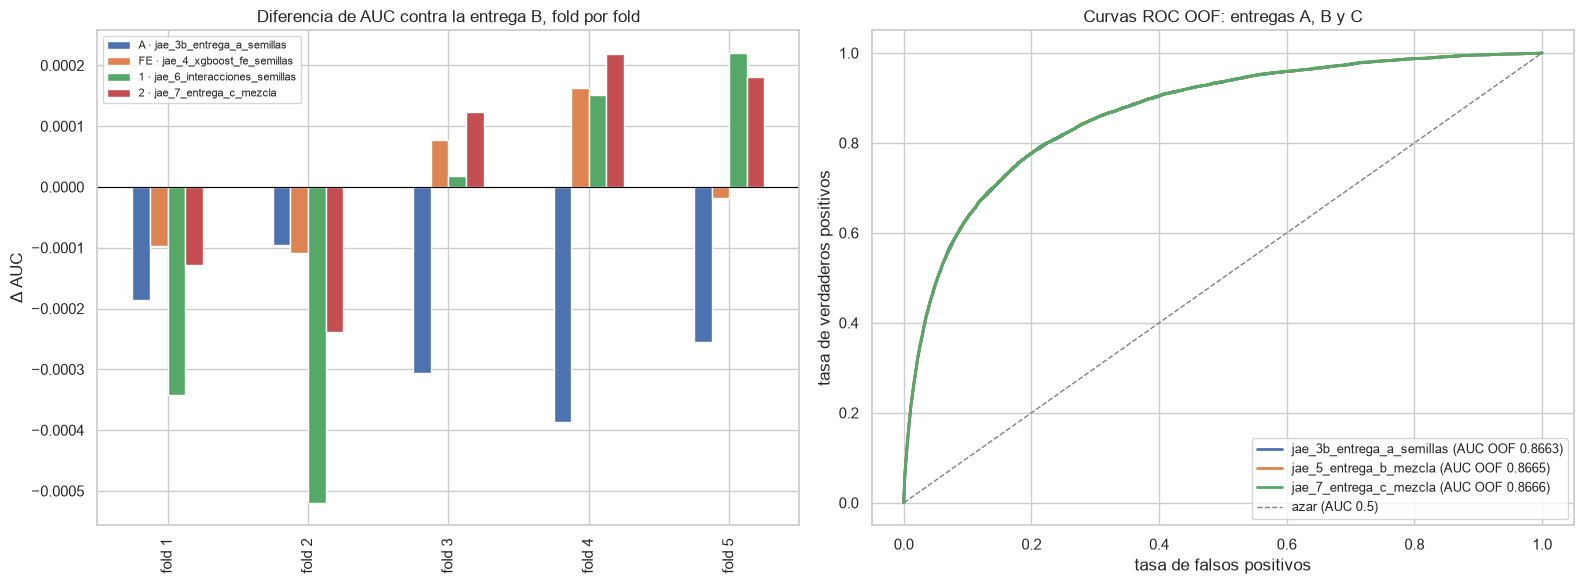

In [10]:
por_fold = pd.DataFrame(
    {f"{k} · {r.nombre}": r.auc_folds for k, r in resultados.items()},
    index=[f"fold {i}" for i in range(1, len(folds) + 1)],
)
display(por_fold.round(5))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
diferencias = por_fold.sub(resultados["B"].auc_folds, axis=0).drop(
    columns=[c for c in por_fold.columns if c.startswith("B ·")]
)
diferencias.plot(kind="bar", ax=axes[0])
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Diferencia de AUC contra la entrega B, fold por fold")
axes[0].set_ylabel("Δ AUC")
axes[0].legend(fontsize=8)
graficar_roc_oof([resultados["A"], resultados["B"], resultados["2"]], y, ax=axes[1])
axes[1].set_title("Curvas ROC OOF: entregas A, B y C")
plt.tight_layout()
plt.show()

**Lectura de la traza:**
- **Del punto de partida a la entrega C no hay mejora real:** A → JAE +
  interacciones: +0.00015; B → C: +0.00003. Ningún cambio supera dos
  errores estándar.
- **Los cuatro modelos ganan y pierden en folds distintos** (gráfica de la
  izquierda): las diferencias contra B son de ±0.0005 por fold, el mismo
  orden que el ruido de la partición.
- **Las curvas ROC son indistinguibles.** Con esto se confirma la meseta de
  ≈ 0.8666 que ya mostraban la búsqueda de hiperparámetros y las mezclas
  con otros modelos.

### Importancia de las interacciones
Ganancia promedio de cada variable en el modelo JAE + interacciones, ajustado
con todo `train` (semilla 985). Indica si el modelo realmente usa las
variables nuevas.

In [11]:
modelo_importancia = modelo_jae(CONFIG_JAE_INT, n_estimators=ARBOLES_JAE).fit(X_jae, y)
ganancia = pd.Series(
    modelo_importancia[-1].get_booster().get_score(importance_type="gain")
).sort_values(ascending=False)
ganancia_relativa = (ganancia / ganancia.sum() * 100).round(2).rename("ganancia (%)")
tabla_ganancia = ganancia_relativa.to_frame()
tabla_ganancia["posición"] = range(1, len(tabla_ganancia) + 1)
tabla_ganancia["interacción nueva"] = tabla_ganancia.index.isin(INTERACTION_FEATURES)
display(tabla_ganancia.head(15))

,ganancia (%),posición,interacción nueva
late_x_util,27.62,1,True
late_severity,19.05,2,False
max_late,14.67,3,True
total_late,7.17,4,False
util_clip,4.64,5,False
late_sentinel,4.51,6,False
late_90,3.45,7,False
util_gt1,2.92,8,False
age_x_util,1.98,9,True
age,1.31,10,False


**Lectura:** el modelo **sí usa** las interacciones: `late_x_util`
pasa a ser la variable de mayor ganancia promedio (≈ 28 %), `max_late` la
tercera (≈ 15 %), `age_x_util` la novena y `non_re_lines` la decimoséptima.
Sin embargo, el AUC casi no cambia: las interacciones **sustituyen** a los
atrasos y a la utilización que ya estaban (`late_severity`, `total_late`,
`util_clip`), en lugar de aportar información nueva. Una variable puede
ser muy usada y aun así no mejorar el modelo.

**Registro en la bitácora del equipo** (`reports/experiments.csv`).

In [12]:
DESCRIPCIONES = {
    "1": (DATASET_JAE_INT, f"XGBoost 2b lr=0.01, {ARBOLES_JAE} árboles, 5 semillas"),
    "2": ("JAE + interacciones + FE", "mezcla 50/50 de jae_6 y jae_4"),
}
for clave, (features, modelo) in DESCRIPCIONES.items():
    registrar_en_bitacora(
        resultados[clave],
        features=features,
        modelo=modelo,
        notas=(
            f"notebooks/06_interacciones_jae; iteración {clave}; "
            f"AUC OOF {resultados[clave].auc_oof:.5f}"
        ),
    )
read_log().sort_values("cv_auc_mean", ascending=False)[
    ["nombre", "modelo", "cv_auc_mean", "cv_auc_std", "kaggle_score"]
].head(8)

,nombre,modelo,cv_auc_mean,cv_auc_std,kaggle_score
13,jae_7_entrega_c_mezcla,mezcla 50/50 de jae_6 y jae_4,0.86666,0.00284,NaN
10,jae_4_xgboost_fe_semillas,"XGBoost 2b lr=0.01, 777 árboles, 5 semillas",0.86663,0.00280,NaN
11,jae_5_entrega_b_mezcla,mezcla 50/50 de jae_3b y jae_4,0.86663,0.00285,NaN
12,jae_6_interacciones_semillas,"XGBoost 2b lr=0.01, 764 árboles, 5 semillas",0.86653,0.00287,NaN
9,jae_3b_entrega_a_semillas,"XGBoost 2b lr=0.01, 764 árboles, 5 semillas",0.86638,0.00289,NaN
8,jae_3a_xgboost_lr001,XGBoost 2b lr=0.01 + ES (≈ 764 árboles),0.86595,0.00299,NaN
6,jae_2b_xgboost_ajustado,"XGBoost {'subsample': 0.6, 'reg_lambda': 10.0, 'min_child_weight': 10, 'max_depth': 6, 'gamma': 0.5, 'colsample_bytree': 0.7} + ES",0.86586,0.00322,0.87992
5,jae_2a_xgboost_base,XGBoost lr=0.05 depth=4 + ES,0.86489,0.00275,NaN


## 7. Entregas
Cada modelo se reentrena con todo `train`, una vez por semilla, y se
promedian las probabilidades sobre `test`:
- **Entrega C:** mezcla 50/50 de JAE + interacciones (5 semillas) y FE (5
  semillas).
- **JAE + interacciones solo:** se guarda como alternativa.

In [13]:
def predecir_semillas(
    crear_modelo: Callable[[int], object],
    X_entrenamiento: pd.DataFrame,
    X_prueba: pd.DataFrame,
) -> np.ndarray:
    """Reentrena el modelo con todo train por cada semilla y promedia en test.

    Args:
        crear_modelo: Función que recibe una semilla y devuelve el modelo sin
            ajustar.
        X_entrenamiento: Variables de todo ``train``.
        X_prueba: Variables de ``test``.

    Returns:
        Probabilidad promedio de las semillas para cada fila de ``test``.
    """
    predicciones = [
        crear_modelo(semilla).fit(X_entrenamiento, y).predict_proba(X_prueba)[:, 1]
        for semilla in SEMILLAS
    ]
    return np.mean(predicciones, axis=0)


def guardar_entrega(probabilidad: np.ndarray, archivo: str) -> pd.DataFrame:
    """Guarda una entrega con el formato de ``sample_submission.csv`` y la verifica.

    Args:
        probabilidad: Probabilidad de morosidad de cada fila de ``test``.
        archivo: Nombre del archivo dentro de ``data/processed/jae/``.

    Returns:
        Entrega guardada.

    Raises:
        AssertionError: Si el formato no coincide con el de la muestra.
    """
    entrega = (
        pd.DataFrame({ID: test_raw[ID].to_numpy(), TARGET: probabilidad})
        .set_index(ID)
        .loc[muestra[ID]]
        .reset_index()
    )
    assert list(entrega.columns) == list(muestra.columns), "Columnas distintas"
    assert len(entrega) == len(muestra), "Número de filas distinto"
    assert (
        entrega[ID].to_numpy() == muestra[ID].to_numpy()
    ).all(), "Orden de Id distinto"
    assert entrega[TARGET].notna().all(), "Hay probabilidades nulas"
    assert entrega[TARGET].between(0, 1).all(), "Probabilidades fuera de [0, 1]"
    entrega.to_csv(SALIDA / archivo, index=False)
    print(
        f"✅ {(SALIDA / archivo).relative_to(ROOT)}: {len(entrega):,} filas, "
        f"media {probabilidad.mean():.4f}, rango {probabilidad.min():.4f}–"
        f"{probabilidad.max():.4f}"
    )
    return entrega


proba_int = predecir_semillas(
    lambda semilla: modelo_jae(
        CONFIG_JAE_INT, n_estimators=ARBOLES_JAE, random_state=semilla
    ),
    X_jae,
    X_jae_test,
)
proba_fe = predecir_semillas(
    lambda semilla: clasificador(n_estimators=ARBOLES_FE, random_state=semilla),
    X_fe,
    X_fe_test,
)
entrega_int = guardar_entrega(proba_int, "submission_jae_interacciones.csv")
entrega_c = guardar_entrega((proba_int + proba_fe) / 2, "submission_c_mezcla.csv")

entrega_b = pd.read_csv(SALIDA / "submission_b_mezcla.csv")
assert (entrega_b[ID].to_numpy() == entrega_c[ID].to_numpy()).all(), "Orden distinto"
display(
    pd.DataFrame(
        {
            "Spearman con la entrega B": [
                entrega_int[TARGET].corr(entrega_b[TARGET], method="spearman"),
                entrega_c[TARGET].corr(entrega_b[TARGET], method="spearman"),
            ]
        },
        index=["JAE + interacciones", "entrega C"],
    ).round(4)
)

pd.DataFrame(
    {
        ID: train_raw[ID],
        "oof_jae_interacciones": resultados["1"].oof,
        "oof_entrega_c": resultados["2"].oof,
        TARGET: y,
    }
).to_parquet(SALIDA / "oof_interacciones_06.parquet", index=False)

✅ data/processed/jae/submission_jae_interacciones.csv: 45,000 filas, media 0.0664, rango 0.0028–0.8542
✅ data/processed/jae/submission_c_mezcla.csv: 45,000 filas, media 0.0665, rango 0.0027–0.8593


,Spearman con la entrega B
JAE + interacciones,0.9992
entrega C,0.9996


**Lectura:** las dos entregas tienen 45,000 filas, el orden de
`Id` de `sample_submission.csv` y probabilidades válidas. Su orden coincide
casi por completo con el de la entrega B (tabla de Spearman), así que en
Kaggle deberían obtener un puntaje muy parecido. Quedan en
`data/processed/jae/`, que no se versiona.

## 8. Conclusiones

1. **Las interacciones de FE mejoran un poco al conjunto JAE**
   (+0.00015 sobre la entrega A), dentro del ruido. Se quedan en el dataset
   de entrenamiento (`train_jae.parquet`, 30 variables) porque no empeoran y
   acercan el conjunto JAE al FE.
2. **La entrega C (0.86666) empata con la entrega B (0.86663).** La B sigue
   siendo la recomendada: tiene la misma validación, gana en los 5 folds a
   2b y ya está probada en Kaggle. La C es una alternativa equivalente.
3. **Una variable muy usada no es una variable que aporte:** `late_x_util`
   encabeza la ganancia, pero sustituye a los atrasos que ya existían.
4. **La meseta de ≈ 0.8666 se confirma por tercera vía:** variables (este
   notebook), hiperparámetros (30 configuraciones sin mejora) y mezclas con
   otros modelos (logística, LightGBM y XGBoost poco profundo).
5. **Cautela con el *leaderboard*:** la distancia con el primer lugar
   (0.88052 contra 0.88012) es de 0.0004, menor que el ruido del puntaje
   público. La selección final debe hacerse con la validación cruzada.

**Siguientes pasos:**
1. Elegir las dos entregas finales con la validación cruzada: B (principal)
   y C o FE solo (alternativa).
2. Si se busca diversidad real, el único modelo pendiente es CatBoost, que
   requiere agregar una dependencia y registrar la decisión en un ADR.